<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and fixture provenance](README.md)

# 01 · One sample can appear in several inclusive totals

How can a shared library have one self sample while its caller appears in every stack? We will decode one small capture, map raw instruction addresses to loaded objects, and compare three counts: **self samples**, **distinct samples containing an object**, and **frame occurrences**. Then we will shorten the retained callchains without changing the capture.

**Explicitly synthetic capture:** the worker repository's deterministic `callchain.data` contains three samples, a process name and two mappings. It was generated for decoder tests, not recorded from a running workload. Repeated addresses within the same object need not denote the same function. This is an accounting example, not a benchmark or evidence of a performance problem.

## Choose a retained stack depth

`MAX_FRAMES` is an integer from **1 to 8**, counting frames from the start of each returned callchain. Default **2** retains the complete fixture; **1** keeps only its first frame. The parameter affects only callchain analysis: the sampled instruction pointer remains available for every sample.

This simulates an analytical depth cutoff after decoding. It does not recapture the workload or repair an already truncated stack. Restart Kernel → Run All after editing.

In [1]:
MAX_FRAMES = 2  # Frames per sample; experiment: 1

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import Patch, Rectangle

assert type(MAX_FRAMES) is int and 1 <= MAX_FRAMES <= 8
fixture = Path("fixtures/callchain.data")
manifest = json.loads(Path("fixtures/provenance.json").read_text())
fixture_hash = hashlib.sha256(fixture.read_bytes()).hexdigest()
assert fixture_hash == manifest["sha256"]
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
colors = {"/usr/bin/loop": "#287d85", "/usr/lib/libc.so.6": "#bd7735", "[unmapped]": "#888888"}


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Synthetic callchain.data · real vgi-perf v0.4.0 decoder · raw addresses, no symbolication",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.89))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-perf/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-perf/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-perf/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-perf/notebooks/pyproject.toml.

## Decode the same bytes into complementary tables

The visible connection downloads the pinned published worker. Each function accepts a constant local path; all results are materialized once for reuse. `meta.total_events` counts capture records, not sampled instructions. Missing header sections remain NULL. In this fixture even the decoded event name/configuration is missing, so we will count samples rather than assign a unit to the recorded sampling period.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'perf' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-perf@v0.4.0');
CREATE TABLE capture_meta AS SELECT * FROM perf.meta('fixtures/callchain.data');
CREATE TABLE capture_events AS SELECT * FROM perf.events('fixtures/callchain.data');
CREATE TABLE mappings AS SELECT row_number() OVER () AS mapping_id,* FROM perf.mmaps('fixtures/callchain.data');
CREATE TABLE comms AS SELECT * FROM perf.comms('fixtures/callchain.data');
CREATE TABLE samples AS
SELECT row_number() OVER (ORDER BY time,pid,tid,ip) AS sample_id,*
FROM perf.samples('fixtures/callchain.data');

,Count


In [4]:
%%sql capture_meta <<
SELECT hostname,arch,nrcpus,perf_version,cmdline,total_events,
 (SELECT count(*) FROM samples) AS sample_records,
 (SELECT count(*) FROM mappings) AS mapping_records,
 (SELECT count(*) FROM comms) AS comm_records FROM capture_meta;

In [5]:
%%sql event_table <<
SELECT event_id,name,type,config,sample_period,sample_freq FROM capture_events ORDER BY event_id;

In [6]:
display(capture_meta)
display(event_table)
assert con.execute(
    "SELECT count(*)>0 AND count(*)=count(DISTINCT (time,pid,tid,ip)) FROM samples"
).fetchone()[0]
assert con.execute("SELECT count(*) FROM mappings WHERE len<=0 OR filename IS NULL").fetchone()[0] == 0
assert (
    con.execute(
        "SELECT count(*) FROM mappings a JOIN mappings b ON a.mapping_id<b.mapping_id AND a.pid=b.pid AND a.addr::HUGEINT < b.addr::HUGEINT+b.len::HUGEINT AND b.addr::HUGEINT<a.addr::HUGEINT+a.len::HUGEINT"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM (SELECT pid FROM comms GROUP BY pid HAVING count(*)>1)").fetchone()[0]
    == 0
)
raw_rows = con.execute("SELECT * FROM samples ORDER BY sample_id").fetchall()
fingerprint = hashlib.sha256(json.dumps(raw_rows, separators=(",", ":")).encode()).hexdigest()
sample_count = len(raw_rows)
missing_chains = con.execute(
    "SELECT count(*) FROM samples WHERE callchain IS NULL OR len(callchain)=0"
).fetchone()[0]
prose(
    f"The decoder returned **{sample_count} samples** from **{int(capture_meta.total_events.iloc[0])} capture records**, including **{int(capture_meta.mapping_records.iloc[0])} mappings** and **{int(capture_meta.comm_records.iloc[0])} process-name record**. **{missing_chains} samples** lack a nonempty callchain. Header NULLs are unknown, not zero-valued measurements. Raw sample fingerprint: `{fingerprint}`."
)

,hostname,arch,nrcpus,perf_version,cmdline,total_events,sample_records,mapping_records,comm_records
0,None,None,<NA>,None,<NA>,6,3,2,1


,event_id,name,type,config,sample_period,sample_freq
0,0,None,hardware,<NA>,4000,<NA>


The decoder returned **3 samples** from **6 capture records**, including **2 mappings** and **1 process-name record**. **0 samples** lack a nonempty callchain. Header NULLs are unknown, not zero-valued measurements. Raw sample fingerprint: `c26afddcce7b06d5406fe7f68fa121aba5ac698a59e7d514487322452e77cc94`.

## Resolve addresses with a half-open mapping range

A mapping owns addresses **`addr <= ip < addr + len`** for its PID. The upper boundary belongs outside that mapping. We use wide arithmetic for the endpoint and LEFT JOINs to retain unmapped addresses. Before joining, we checked that mappings do not overlap within a PID; otherwise one instruction could silently multiply into several rows.

The worker does not expose mapping timestamps, so this simple join is appropriate for the fixture's static mappings. A real capture with address reuse, unloads or PID reuse needs time-aware resolution that these columns alone cannot establish. The paths identify mapped objects, not resolved function names.

In [7]:
%%sql mapping_table <<
SELECT pid,filename,'0x'||hex(addr) AS start_inclusive,
 '0x'||hex(addr::HUGEINT+len::HUGEINT) AS end_exclusive,len AS mapped_bytes,build_id
FROM mappings ORDER BY pid,addr;

In [8]:
%%sql
CREATE TABLE self_samples AS
SELECT s.sample_id,s.time,s.pid,s.tid,s.cpu,s.ip,s.period,
 coalesce(m.filename,'[unmapped]') AS object
FROM samples s LEFT JOIN mappings m ON s.pid=m.pid
 AND s.ip::HUGEINT>=m.addr::HUGEINT
 AND s.ip::HUGEINT<m.addr::HUGEINT+m.len::HUGEINT;
CREATE TABLE frames AS
SELECT s.sample_id,s.pid,f.ordinality AS frame_position,f.ip,
 coalesce(m.filename,'[unmapped]') AS object,
 f.ordinality<={{MAX_FRAMES}} AS retained
FROM samples s CROSS JOIN UNNEST(s.callchain) WITH ORDINALITY AS f(ip,ordinality)
LEFT JOIN mappings m ON s.pid=m.pid AND f.ip::HUGEINT>=m.addr::HUGEINT
 AND f.ip::HUGEINT<m.addr::HUGEINT+m.len::HUGEINT;

,Count


,pid,filename,start_inclusive,end_exclusive,mapped_bytes,build_id
0,1234,/usr/bin/loop,0x400000,0x401000,4096,aaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaaa
1,1234,/usr/lib/libc.so.6,0x7F0000000000,0x7F0000200000,2097152,bbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbb


The raw callchains contain **5 frame occurrences**. With `MAX_FRAMES=2`, **5** are retained and **0** omitted. **0 raw frames** and **0 self instructions** are unmapped. In this fixture every first frame matches its sampled instruction pointer; later frames add caller context.

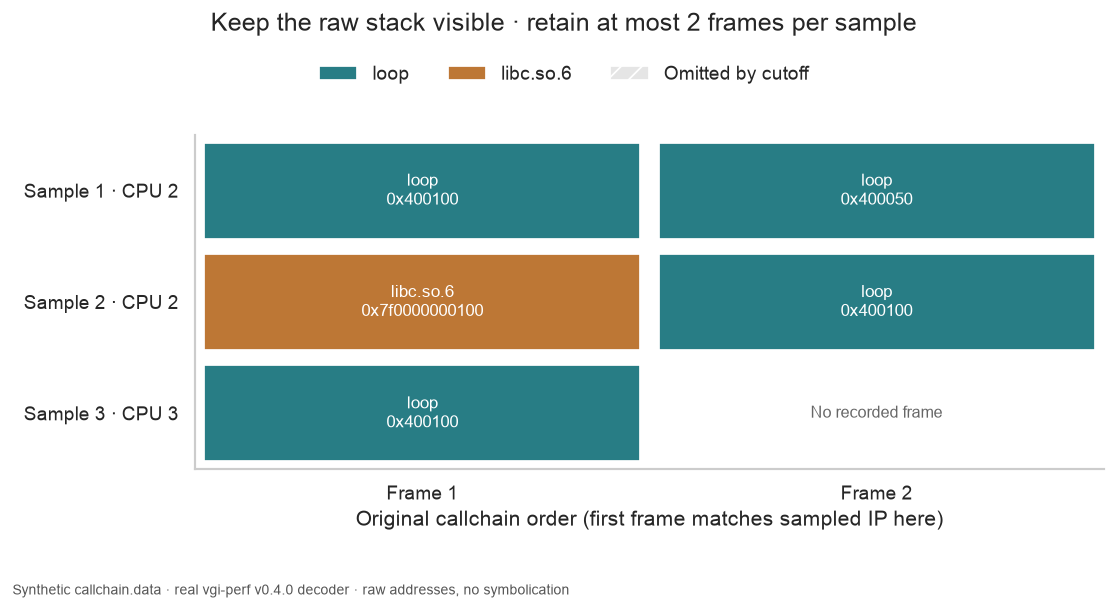

In [9]:
display(mapping_table)
assert con.execute("SELECT count(*) FROM self_samples").fetchone()[0] == sample_count
assert (
    con.execute("SELECT count(*) FROM frames").fetchone()[0]
    == con.execute("SELECT coalesce(sum(len(callchain)),0) FROM samples").fetchone()[0]
)
assert (
    con.execute(
        "SELECT count(*) FROM frames WHERE frame_position=1 AND ip IS DISTINCT FROM (SELECT s.ip FROM samples s WHERE s.sample_id=frames.sample_id)"
    ).fetchone()[0]
    == 0
)
frame_data = con.execute("SELECT * FROM frames ORDER BY sample_id,frame_position").df()
self_data = con.execute("SELECT * FROM self_samples ORDER BY sample_id").df()
retained = int(frame_data.retained.sum())
discarded = len(frame_data) - retained
unmapped = int((frame_data.object == "[unmapped]").sum())
assert retained + discarded == len(frame_data)
prose(
    f"The raw callchains contain **{len(frame_data)} frame occurrences**. With `MAX_FRAMES={MAX_FRAMES}`, **{retained}** are retained and **{discarded}** omitted. **{unmapped} raw frames** and **{int((self_data.object == '[unmapped]').sum())} self instructions** are unmapped. In this fixture every first frame matches its sampled instruction pointer; later frames add caller context."
)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.grid(False)
max_depth = int(frame_data.frame_position.max())
for row in frame_data.itertuples():
    x = row.frame_position - 1
    y = row.sample_id - 1
    color = colors.get(row.object, "#888888") if row.retained else "#e5e5e5"
    ax.add_patch(
        Rectangle(
            (x - 0.48, y - 0.43),
            0.96,
            0.86,
            facecolor=color,
            edgecolor="white",
            hatch=None if row.retained else "//",
        )
    )
    name = Path(row.object).name
    text = f"{name}\n0x{row.ip:x}" + ("\nOmitted" if not row.retained else "")
    ax.text(x, y, text, ha="center", va="center", fontsize=10, color="white" if row.retained else "#333333")
for row in self_data.itertuples():
    for pos in range(1, max_depth + 1):
        if not ((frame_data.sample_id == row.sample_id) & (frame_data.frame_position == pos)).any():
            ax.text(
                pos - 1,
                row.sample_id - 1,
                "No recorded frame",
                ha="center",
                va="center",
                fontsize=9,
                color="#666666",
            )
ax.set(
    xlim=(-0.5, max_depth - 0.5),
    ylim=(sample_count - 0.5, -0.5),
    xticks=range(max_depth),
    xticklabels=[f"Frame {i + 1}" for i in range(max_depth)],
    yticks=range(sample_count),
    yticklabels=[f"Sample {r.sample_id} · CPU {r.cpu}" for r in self_data.itertuples()],
    xlabel="Original callchain order (first frame matches sampled IP here)",
)
fig.suptitle(f"Keep the raw stack visible · retain at most {MAX_FRAMES} frames per sample")
fig.legend(
    handles=[Patch(facecolor=colors[k], label=Path(k).name) for k in colors if k != "[unmapped]"]
    + [Patch(facecolor="#e5e5e5", hatch="//", label="Omitted by cutoff")],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.92),
    ncol=3,
    frameon=False,
)
finish(fig)

## Count each object three ways

**Self samples** assign each sampled IP to one object. **Inclusive samples** count distinct samples with at least one retained frame in that object. **Frame occurrences** count every retained frame, including repeated appearances of the same object in a stack.

Inclusive counts overlap across objects, so summing their percentages would not partition the capture. Frame counts additionally weight stacks with repeated object appearances. Neither count measures elapsed time. The fixture's equal `period` values do not justify converting these counts into seconds.

In [10]:
%%sql
CREATE TABLE comparison AS
WITH objects AS (SELECT object FROM self_samples UNION SELECT object FROM frames),
 self_counts AS (SELECT object,count(*) AS self_samples FROM self_samples GROUP BY object),
 stack_counts AS (
 SELECT object,count(DISTINCT sample_id) FILTER(WHERE retained) AS inclusive_samples,
 count(*) FILTER(WHERE retained) AS frame_occurrences FROM frames GROUP BY object
)
SELECT o.object,coalesce(s.self_samples,0) AS self_samples,
 coalesce(f.inclusive_samples,0) AS inclusive_samples,
 coalesce(f.frame_occurrences,0) AS frame_occurrences
FROM objects o LEFT JOIN self_counts s USING(object) LEFT JOIN stack_counts f USING(object);

,Count


In [11]:
%%sql comparison <<
SELECT object,self_samples,inclusive_samples,frame_occurrences,
 round(100.0*self_samples/(SELECT count(*) FROM samples),1) AS self_pct_of_all_samples,
 round(100.0*inclusive_samples/(SELECT count(*) FROM samples),1) AS inclusive_pct_of_all_samples
FROM comparison ORDER BY object;

,object,self_samples,inclusive_samples,frame_occurrences,self_pct_of_all_samples,inclusive_pct_of_all_samples
0,/usr/bin/loop,2,3,4,66.7,100.0
1,/usr/lib/libc.so.6,1,1,1,33.3,33.3


Across objects, the exclusive self counts sum to **3 samples**. Inclusive counts sum to **4 sample–object pairs**, and retained frames to **5 occurrences**. The difference of **1** between occurrences and pairs comes from repeated frames in the same object within one sample. A repeated object is not enough to infer recursion: its frames can belong to different functions.

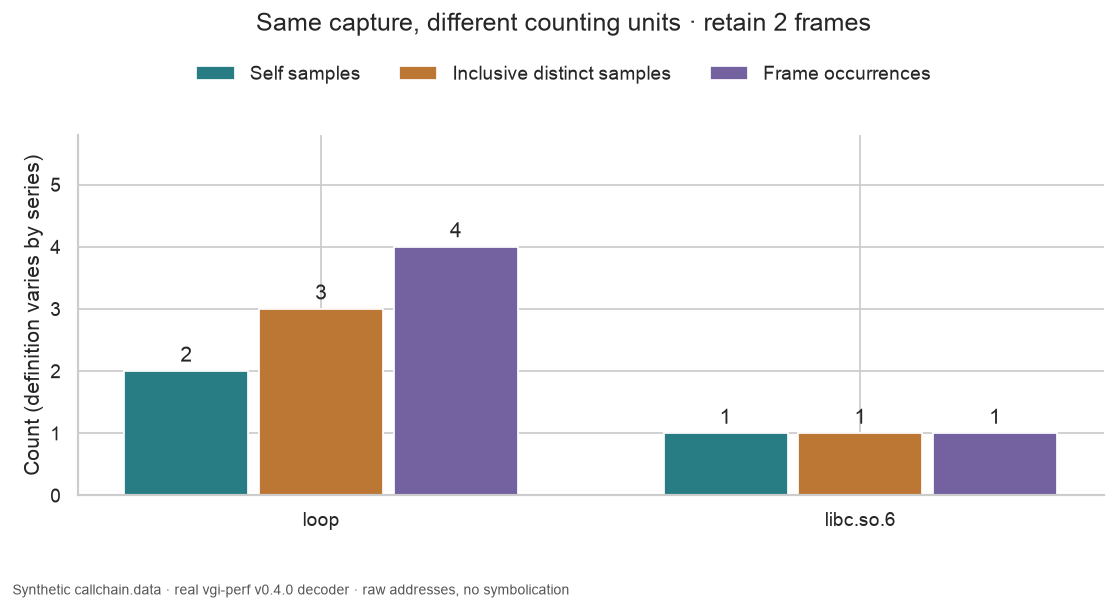

763

In [12]:
display(comparison)
assert comparison.self_samples.sum() == sample_count
assert comparison.frame_occurrences.sum() == retained
assert (comparison.inclusive_samples <= sample_count).all()
assert (comparison.frame_occurrences >= comparison.inclusive_samples).all()
assert (
    con.execute(
        "SELECT count(*) FROM frames f JOIN self_samples s USING(sample_id) WHERE f.retained AND f.frame_position=1 AND f.object IS DISTINCT FROM s.object"
    ).fetchone()[0]
    == 0
)
inclusive_total = int(comparison.inclusive_samples.sum())
repeat_total = int(comparison.frame_occurrences.sum() - inclusive_total)
prose(
    f"Across objects, the exclusive self counts sum to **{sample_count} samples**. Inclusive counts sum to **{inclusive_total} sample–object pairs**, and retained frames to **{retained} occurrences**. The difference of **{repeat_total}** between occurrences and pairs comes from repeated frames in the same object within one sample. A repeated object is not enough to infer recursion: its frames can belong to different functions."
)
x = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(9, 4.8))
for j, (column, label, color) in enumerate(
    [
        ("self_samples", "Self samples", "#287d85"),
        ("inclusive_samples", "Inclusive distinct samples", "#bd7735"),
        ("frame_occurrences", "Frame occurrences", "#7462a0"),
    ]
):
    bars = ax.bar(x + (j - 1) * 0.25, comparison[column], width=0.23, label=label, color=color)
    ax.bar_label(bars, fmt="%d", padding=3)
ax.set(
    xticks=x,
    xticklabels=[Path(v).name for v in comparison.object],
    ylabel="Count (definition varies by series)",
    ylim=(0, max(sample_count, len(frame_data)) + 0.8),
)
ax.yaxis.get_major_locator().set_params(integer=True)
fig.suptitle(f"Same capture, different counting units · retain {MAX_FRAMES} frames")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=3, frameon=False)
finish(fig)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "fixture_sha256": fixture_hash,
            "sample_fingerprint": fingerprint,
            "max_frames": MAX_FRAMES,
            "samples": sample_count,
            "raw_frames": len(frame_data),
            "retained_frames": retained,
            "discarded_frames": discarded,
            "inclusive_pairs": inclusive_total,
            "comparison": comparison.to_dict(orient="records"),
        },
        indent=2,
    )
)

## Experiment: retain only the first frame

Change only `MAX_FRAMES` from **2 to 1**. Predict that self counts stay identical, while inclusive counts and frame occurrences cannot increase. Compare both charts: the grey cells identify the caller evidence removed by the cutoff, and the grouped bars show which object loses that evidence.

The input hash, raw sample fingerprint, mapping table and sample population must remain unchanged. Restore **2** afterwards. This synthetic example illustrates how a depth policy changes attribution; it cannot estimate the bias of any real profiler. SQL success also does not prove that a real capture was complete: the decoder can retain good records after a malformed tail, and these SQL tables do not expose its internal decode-error collection.

In [13]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)